###  TypeError: Cannot interpret '<attribute 'dtype' of 'numpy.generic' objects>' as a data type 
#### 가 발생하는 경우가 있습니다. 이것은 pandas 버전과 numpy의 버전이 맞지않은 경우에 발생합니다.
#### 위의 에러가 발생하는 경우에는, 
#### (1) pip 버전 업그레이드 : (anaconda prompt "관리자권한 실행" 후) python.exe -m pip install --upgrade pip
#### (2) pandas 버전 업그레이드 : (Jupyter Notebook "관리자권한 실행" 후) !pip install pandas --upgrade
#### (3) numpy 버전 업그레이드 :  (Jupyter Notebook "관리자권한 실행" 후) !pip install numpy --upgrade
#### 를 하시기 바랍니다.

In [4]:
from bs4 import BeautifulSoup
import urllib.request
import pandas as pd
import datetime
import requests
from selenium import webdriver
from selenium.webdriver.common.by import By
import time
import random
import matplotlib as mp
import numpy as np
import seaborn as sns
import math

In [121]:
#버전 차이로 인한 warning문구 생략
import warnings
warnings.filterwarnings(action='ignore')

# 7장. 통계분석

# [1] 와인 품질 등급 예측하기

#### p.201
## 4. 데이터준비
### 4.1 다운로드한 CSV 파일 정리하기

### 독립변수x 와 종속변수 y
## y = a1x + a2x2 등등
### t-검정 실제로 두 그룹 간에 차이가 있는지 확인하는 방법 - 수학적 검증 방법(품질이 1등급,2등급에 따라 가격차이가 있는지 등)
### ex) 남성 그룹과 여성 그룹의 차이가 있는/ 약을 먹은 그룹과 먹지 않은 그룹의 상태 차이 등
###
 히스토그램 - 구간 bin으로 나누어주고 해당하는 값 시각화 그냥 막대그래프인듯

In [1]:
import pandas as pd

In [6]:
#sep=';' 구분자, header=0 첫번째 줄 컬럼명으로 지명
#engine = 'python'은 가끔 인코딩 오류를 방지하기 위해 설정했지만 안써놓고 있다가 발생하면 넣어도 된다.
red_df = pd.read_csv('./7장_data/winequality-red.csv', sep = ';', header = 0, engine = 'python')
red_df.head(0)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality


In [7]:
white_df = pd.read_csv('./7장_data/winequality-white.csv', sep = ';', header = 0, engine= 'python')
white_df.head(0)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality


In [8]:
red_df.to_csv('./7장_data/winequality-red2.csv',index = False)

In [9]:
white_df.to_csv('./7장_data/winequality-white2.csv', index = False)

### 4.2 데이터 병합하기

In [7]:
red_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [10]:
red_df.insert(0, column = 'type', value = 'red')

In [12]:
red_df.head()  #작업 확인용 출력

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,red,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,red,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,red,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,red,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,red,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [9]:
red_df.shape

(1599, 13)

In [13]:
white_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [11]:
white_df.insert(0, column = 'type', value = 'white')

In [15]:
white_df.head()    #작업 확인용 출력

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [13]:
white_df.shape

(4898, 13)

In [12]:
wine = pd.concat([red_df, white_df])

In [17]:
wine.shape

(6497, 13)

In [13]:
wine.sort_values('quality',ascending=False).head(10)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1605,white,7.1,0.26,0.49,2.2,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,9
876,white,6.9,0.36,0.34,4.2,0.018,57.0,119.0,0.98980,3.28,0.36,12.7,9
820,white,6.6,0.36,0.29,1.6,0.021,24.0,85.0,0.98965,3.41,0.61,12.4,9
827,white,7.4,0.24,0.36,2.0,0.031,27.0,139.0,0.99055,3.28,0.48,12.5,9
774,white,9.1,0.27,0.45,10.6,0.035,28.0,124.0,0.99700,3.20,0.46,10.4,9
1464,white,8.0,0.44,0.49,9.1,0.031,46.0,151.0,0.99260,3.16,0.27,12.7,8
1715,white,6.5,0.18,0.34,1.6,0.040,43.0,148.0,0.99120,3.32,0.59,11.5,8
1406,white,8.2,0.22,0.36,6.8,0.034,12.0,90.0,0.99440,3.01,0.38,10.5,8
2522,white,7.3,0.17,0.24,8.1,0.121,32.0,162.0,0.99508,3.17,0.38,10.4,8
2525,white,7.3,0.17,0.24,8.1,0.121,32.0,162.0,0.99508,3.17,0.38,10.4,8


In [14]:
wine.to_csv('./7장_data/wine.csv', index = False)

## 5. 데이터 탐색

In [27]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6497 entries, 0 to 4897
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 710.6+ KB


#### 컬럼이름의 띄어쓰기를 밑줄로 바꾸기

In [16]:
wine.columns = wine.columns.str.replace(' ', '_')

In [17]:
wine.head()  #작업 확인용 출력

,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,red,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,red,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,red,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,red,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,red,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [18]:
wine.describe

<bound method NDFrame.describe of        type  fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \
0       red            7.4              0.70         0.00             1.9   
1       red            7.8              0.88         0.00             2.6   
2       red            7.8              0.76         0.04             2.3   
3       red           11.2              0.28         0.56             1.9   
4       red            7.4              0.70         0.00             1.9   
...     ...            ...               ...          ...             ...   
4893  white            6.2              0.21         0.29             1.6   
4894  white            6.6              0.32         0.36             8.0   
4895  white            6.5              0.24         0.19             1.2   
4896  white            5.5              0.29         0.30             1.1   
4897  white            6.0              0.21         0.38             0.8   

      chlorides  free_sulfur_dioxide  tot

In [41]:
sorted(wine.quality.unique())

[np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9)]

In [45]:
wine.quality.value_counts()

quality
6    2836
5    2138
7    1079
4     216
8     193
3      30
9       5
Name: count, dtype: int64

## 6. 데이터 모델링

### 6.1 describe( ) 함수로 그룹 비교하기

In [47]:
wine.groupby('type')['quality'].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
red,1599.0,5.636023,0.807569,3.0,5.0,6.0,6.0,8.0
white,4898.0,5.877909,0.885639,3.0,5.0,6.0,6.0,9.0


In [44]:
wine.groupby('type')['quality'].mean()

type
red      5.636023
white    5.877909
Name: quality, dtype: float64

In [25]:
wine.groupby('type')['quality'].std()

type
red      0.807569
white    0.885639
Name: quality, dtype: float64

In [26]:
wine.groupby('type')['quality'].agg(['mean', 'std'])

,mean,std
type,,
red,5.636023,0.807569
white,5.877909,0.885639


### 6.2 t-검정과 회귀 분석으로 그룹 비교하기

In [46]:
# 통계 라이브러리 설치 : 한번만 실행
!pip install statsmodels

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.6 MB 6.3 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.6 MB 5.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.6 MB 5.8 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.6 MB 5.8 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.6 MB 6.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 MB 6.3 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.6 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 6.1 MB/s  0:00:01
   ---------------------------------------- 0.0/37.3 MB ? eta -:--:--
   - -------------------------------------- 1.3/37.3 MB 7.4 MB/s eta 0:00:05
   --- ------------------------------------ 2.9/37.3 MB 7.8 MB/s eta 0:00:05
   ---- ----------------------------------- 4.5/37.3 MB 7.6 MB/s eta 0:00:05
   ------ ---------------

In [1]:
from scipy import stats

In [ ]:
#최소 제곱, 선형회귀 위한 모듈
from statsmodels.formula.api import ols, glm

In [19]:
red_wine_quality = wine.loc[wine['type'] == 'red', 'quality']

In [20]:
white_wine_quality = wine.loc[wine['type'] == 'white', 'quality']

In [ ]:
#독립표본 t-검정
#레드와인과 화이트와인의 평균 품질이 통계적으로 차이가 있는지 검정
stats.ttest_ind(red_wine_quality, white_wine_quality, equal_var = False)

TtestResult(statistic=np.float64(-10.149363059143164), pvalue=np.float64(8.168348870049669e-24), df=np.float64(2950.750452166697))

In [22]:
Rformula = 'quality ~ fixed_acidity + volatile_acidity + citric_acid + \
            residual_sugar + chlorides + free_sulfur_dioxide + \
            total_sulfur_dioxide + density + pH + sulphates + alcohol'

In [23]:
regression_result = ols(Rformula, data = wine).fit()

In [ ]:
#선택한 x 독립변수의 개수도 세주고 여러가지 요약을 확인할 수 있다. 가장 중요한 것은 r-squared이다
#r-squared 란 100개의 데이터가 있으면 r-squared 만큼의 비율은 해당 계산으로 설명이 가능하다는 뜻이다.
regression_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                quality   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     243.3
Date:                Thu, 11 Jun 2026   Prob (F-statistic):               0.00
Time:                        14:27:41   Log-Likelihood:                -7215.5
No. Observations:                6497   AIC:                         1.445e+04
Df Residuals:                    6485   BIC:                         1.454e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               55.7627     11.894      4.688      0.000      32.447      79.079
fixed_acidity            0.0677      0.016      4.346      0.000       0.037       0.098
volatile_acidity        -1.3279      0.077    -17.162      0.000      -1.480      -1.176
citric_acid             -0.1097      0.080     -1.377      0.168      -0.266       0.046
residual_sugar           0.0436      0.005      8.449      0.000       0.033       0.054
chlorides               -0.4837      0.333     -1.454      0.146      -1.136       0.168
free_sulfur_dioxide      0.0060      0.001      7.948      0.000       0.004       0.007
total_sulfur_dioxide    -0.0025      0.000     -8.969      0.000      -0.003      -0.002
density                -54.9669     12.137     -4.529      0.000     -78.760     -31.173
pH                       0.4393      0.090      4.861      0.000       0.262       0.616
sulphates                0.7683      0.076     10.092      0.000       0.619       0.917
alcohol                  0.2670      0.017     15.963      0.000       0.234       0.300
==============================================================================
Omnibus:                      144.075   Durbin-Watson:                   1.646
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              324.712
Skew:                          -0.006   Prob(JB):                     3.09e-71
Kurtosis:                       4.095   Cond. No.                     2.49e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.49e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### 6.3 회귀 분석 모델로 새로운 샘플의 품질 등급 예측하기

In [25]:
sample1 = wine[wine.columns.difference(['quality', 'type'])]

In [26]:
sample1 = sample1[0:5][:]
sample1

,alcohol,chlorides,citric_acid,density,fixed_acidity,free_sulfur_dioxide,pH,residual_sugar,sulphates,total_sulfur_dioxide,volatile_acidity
0,9.4,0.076,0.00,0.9978,7.4,11.0,3.51,1.9,0.56,34.0,0.70
1,9.8,0.098,0.00,0.9968,7.8,25.0,3.20,2.6,0.68,67.0,0.88
2,9.8,0.092,0.04,0.9970,7.8,15.0,3.26,2.3,0.65,54.0,0.76
3,9.8,0.075,0.56,0.9980,11.2,17.0,3.16,1.9,0.58,60.0,0.28
4,9.4,0.076,0.00,0.9978,7.4,11.0,3.51,1.9,0.56,34.0,0.70


In [27]:
sample1_predict = regression_result.predict(sample1)

In [28]:
sample1_predict

0    4.997607
1    4.924993
2    5.034663
3    5.680333
4    4.997607
dtype: float64

In [29]:
wine[0:5]['quality']

0    5
1    5
2    5
3    6
4    5
Name: quality, dtype: int64

### - 임의의 data로 샘플 만들기

In [30]:
data = {"fixed_acidity" : [8.5, 8.1], "volatile_acidity":[0.8, 0.5],
"citric_acid":[0.3, 0.4], "residual_sugar":[6.1, 5.8], "chlorides":[0.055,
0.04], "free_sulfur_dioxide":[30.0, 31.0], "total_sulfur_dioxide":[98.0,
99], "density":[0.996, 0.91], "pH":[3.25, 3.01], "sulphates":[0.4, 0.35],
"alcohol":[9.0, 0.88]}

In [31]:
sample2 = pd.DataFrame(data, columns= sample1.columns)

In [32]:
sample2

,alcohol,chlorides,citric_acid,density,fixed_acidity,free_sulfur_dioxide,pH,residual_sugar,sulphates,total_sulfur_dioxide,volatile_acidity
0,9.00,0.055,0.3,0.996,8.5,30.0,3.25,6.1,0.40,98.0,0.8
1,0.88,0.040,0.4,0.910,8.1,31.0,3.01,5.8,0.35,99.0,0.5


In [33]:
sample2_predict = regression_result.predict(sample2)

In [34]:
sample2_predict

0    4.809094
1    7.582129
dtype: float64

## 7. 결과 시각화

### 7.1 와인 유형에 따른 품질 등급 히스토그램 그리기

In [ ]:
#  라이브러리 설치 : 한번만 실행
!pip install seaborn

In [35]:
import matplotlib.pyplot as plt

In [36]:
import seaborn as sns

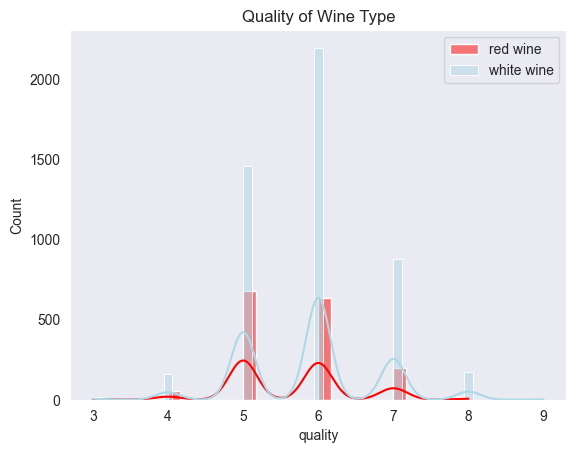

In [54]:
sns.set_style('dark')
sns.histplot(red_wine_quality, kde = True, color = "red", label = 'red wine')
sns.histplot(white_wine_quality, kde = True, color='lightblue' ,label = 'white wine')
plt.title("Quality of Wine Type")
plt.legend()
plt.show()

### 7.2 부분 회귀 플롯으로 시각화하기

In [57]:
import statsmodels.api as sm

### - fixed_acidity가 종속 변수 quality에 미치는 영향력을 시각화하기

In [58]:
others = list(set(wine.columns).difference(set(["quality", "fixed_acidity"])))

(array([-0.0614815 , -0.02284876, -0.14904951, ..., -0.63960939,
       -0.27128396, -0.13872942], shape=(6497,)), array([ 0.02363191,  0.08667536, -0.04281161, ...,  0.55410286,
        0.5178791 , -0.2565605 ], shape=(6497,)))


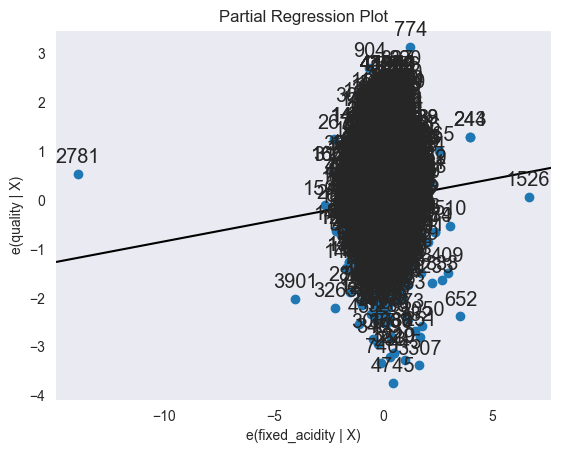

In [ ]:
#plot_partregress의 그래프는 경향에 맞게 선을 그어준다.
p, resids = sm.graphics.plot_partregress("quality", "fixed_acidity", others, data = wine, ret_coords = True)
print(resids)

### - 각 독립 변수가 종속 변수 quality에 미치는 영향력을 시각화하기

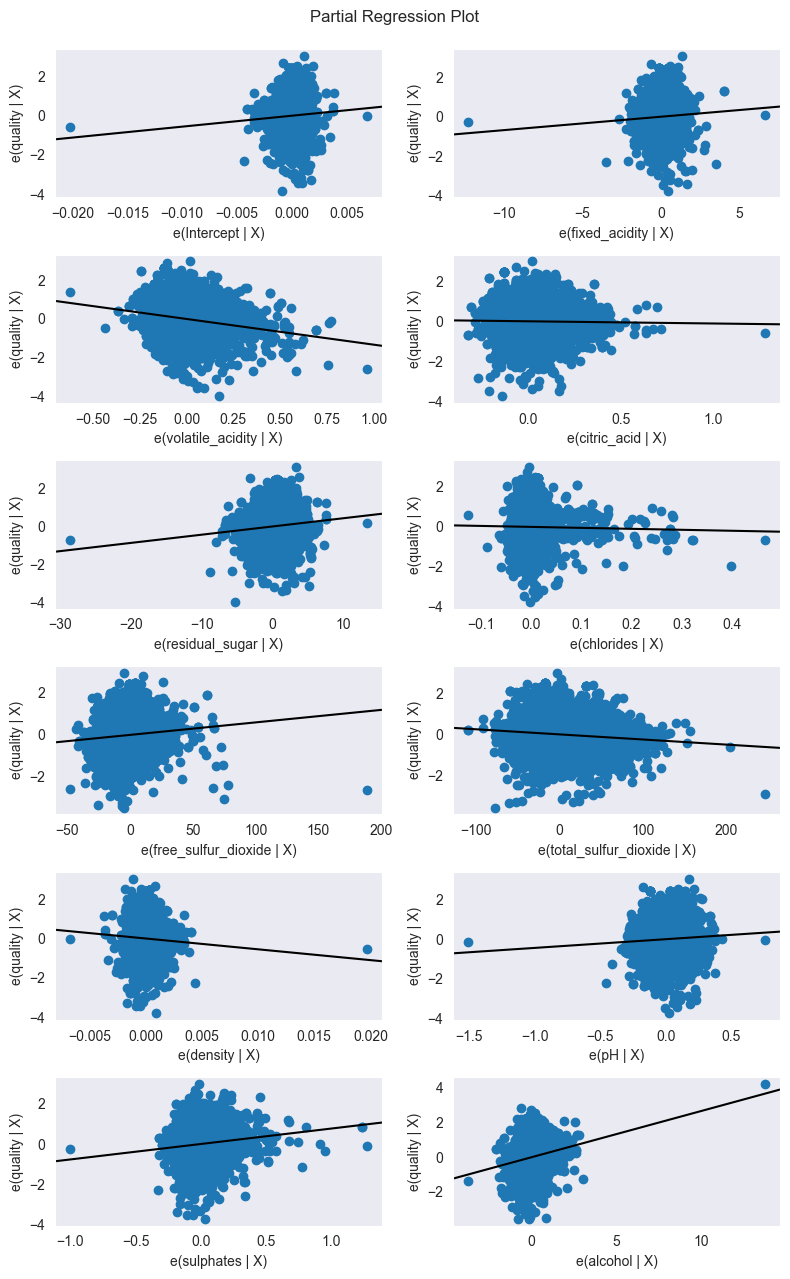

In [62]:
fig = plt.figure(figsize = (8, 13))
sm.graphics.plot_partregress_grid(regression_result, fig = fig)
plt.show()

------------------------------------------

# [2] 상관분석 + 히트맵
#      타이타닉호 생존율 분석하기

## 3. 데이터 수집

In [2]:
import seaborn as sns

In [3]:
import pandas as pd

In [16]:
titanic = sns.load_dataset("titanic")

In [5]:
titanic.to_csv('./7장_data/titanic.csv', index = False)

## 4. 데이터 준비

#### - 결측값 있는지 확인하기

In [17]:
#count나 이런경우에는 false값도 다 가져오므로 null값인 1을 찾아서 sum해준다.
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [18]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


#### - age 열의 결측값을 중앙값으로 치환하기

In [19]:
titanic['age'] = titanic['age'].fillna(titanic['age'].median())

#### - embarked 열의 결측값을 최빈값으로 치환하기
##### 최빈값 먼저 확인해서 해당 값 fillna로 넣어주기

In [20]:
titanic['embarked'].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [21]:
titanic['embarked'] = titanic['embarked'].fillna('S')

#### - embark_town 열의 결측값을 최빈값으로 치환하기

In [22]:
titanic['embark_town'].value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [23]:
titanic['embark_town'] = titanic['embark_town'].fillna('Southampton')

#### - deck 열의 결측값을 최빈값으로 치환하기

In [62]:
titanic['deck'].value_counts()

deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64

In [26]:
titanic['deck'] = titanic['deck'].fillna('C')

#### - 결측치가 다 채워졌는지 확인하기

In [28]:
titanic.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64

## 5. 데이터 탐색

### 5.1 데이터의 기본 정보 탐색하기

In [29]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         891 non-null    category
 12  embark_town  891 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [30]:
titanic.survived.value_counts()

survived
0    549
1    342
Name: count, dtype: int64

### 5.2 차트를 그려 데이터를 시각적으로 탐색하기

In [31]:
import matplotlib.pyplot as plt

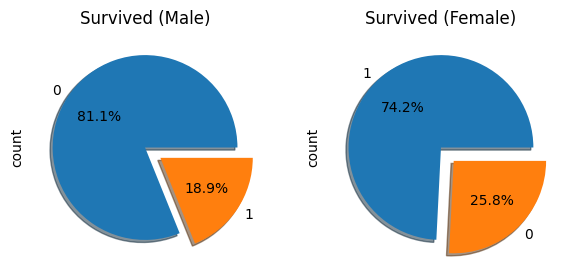

In [39]:
f,ax = plt.subplots(1, 2, figsize = (7, 3))

titanic['survived'][titanic['sex'] == 'male'].value_counts().plot.pie(explode = [0,0.2], autopct = '%1.1f%%', ax = ax[0], shadow = True)
titanic['survived'][titanic['sex'] == 'female'].value_counts().plot.pie(explode = [0,0.2], autopct = '%1.1f%%', ax = ax[1], shadow = True)
ax[0].set_title('Survived (Male)')
ax[1].set_title('Survived (Female)')

plt.show()

### 5.3 등급별 생존자 수를 차트로 나타내기

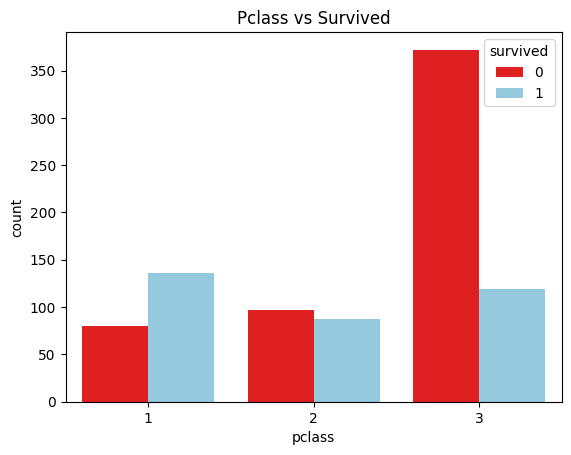

In [50]:
#countplot 갯수를 세서 막대그래프로 보여준다.
sns.countplot(x='pclass', hue = 'survived', data = titanic, palette=['red','skyblue'])
plt.title('Pclass vs Survived')
plt.show()

## 6. 데이터 모델링

### 6.1 상관분석을 위한 상관계수를 구하고 저장하기

In [51]:
titanic2 = titanic.select_dtypes(include=[int, float,bool]) 
titanic2.shape

(891, 8)

In [52]:
titanic_corr = titanic2.corr(method = 'pearson')

In [53]:
titanic_corr

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
survived,1.000000,-0.338481,-0.064910,-0.035322,0.081629,0.257307,-0.557080,-0.203367
pclass,-0.338481,1.000000,-0.339898,0.083081,0.018443,-0.549500,0.094035,0.135207
age,-0.064910,-0.339898,1.000000,-0.233296,-0.172482,0.096688,0.247704,0.171647
sibsp,-0.035322,0.083081,-0.233296,1.000000,0.414838,0.159651,-0.253586,-0.584471
parch,0.081629,0.018443,-0.172482,0.414838,1.000000,0.216225,-0.349943,-0.583398
fare,0.257307,-0.549500,0.096688,0.159651,0.216225,1.000000,-0.182024,-0.271832
adult_male,-0.557080,0.094035,0.247704,-0.253586,-0.349943,-0.182024,1.000000,0.404744
alone,-0.203367,0.135207,0.171647,-0.584471,-0.583398,-0.271832,0.404744,1.000000


In [73]:
titanic_corr.to_csv('./7장_data/titanic_corr.csv', index = False)

### 6.2 상관계수 확인하기 

#### - 저장한 titanic_corr.csv 파일을 열어서 저장된 상관계수를 확인해본다

### 6.3 특정 변수 사이의 상관계수 구하기 

In [54]:
titanic['survived'].corr(titanic['adult_male'])

np.float64(-0.5570800422053259)

In [55]:
titanic['survived'].corr(titanic['fare'])

np.float64(0.2573065223849622)

## 7. 결과 시각화

### 7.1 산점도로 상관 분석 시각화하기 

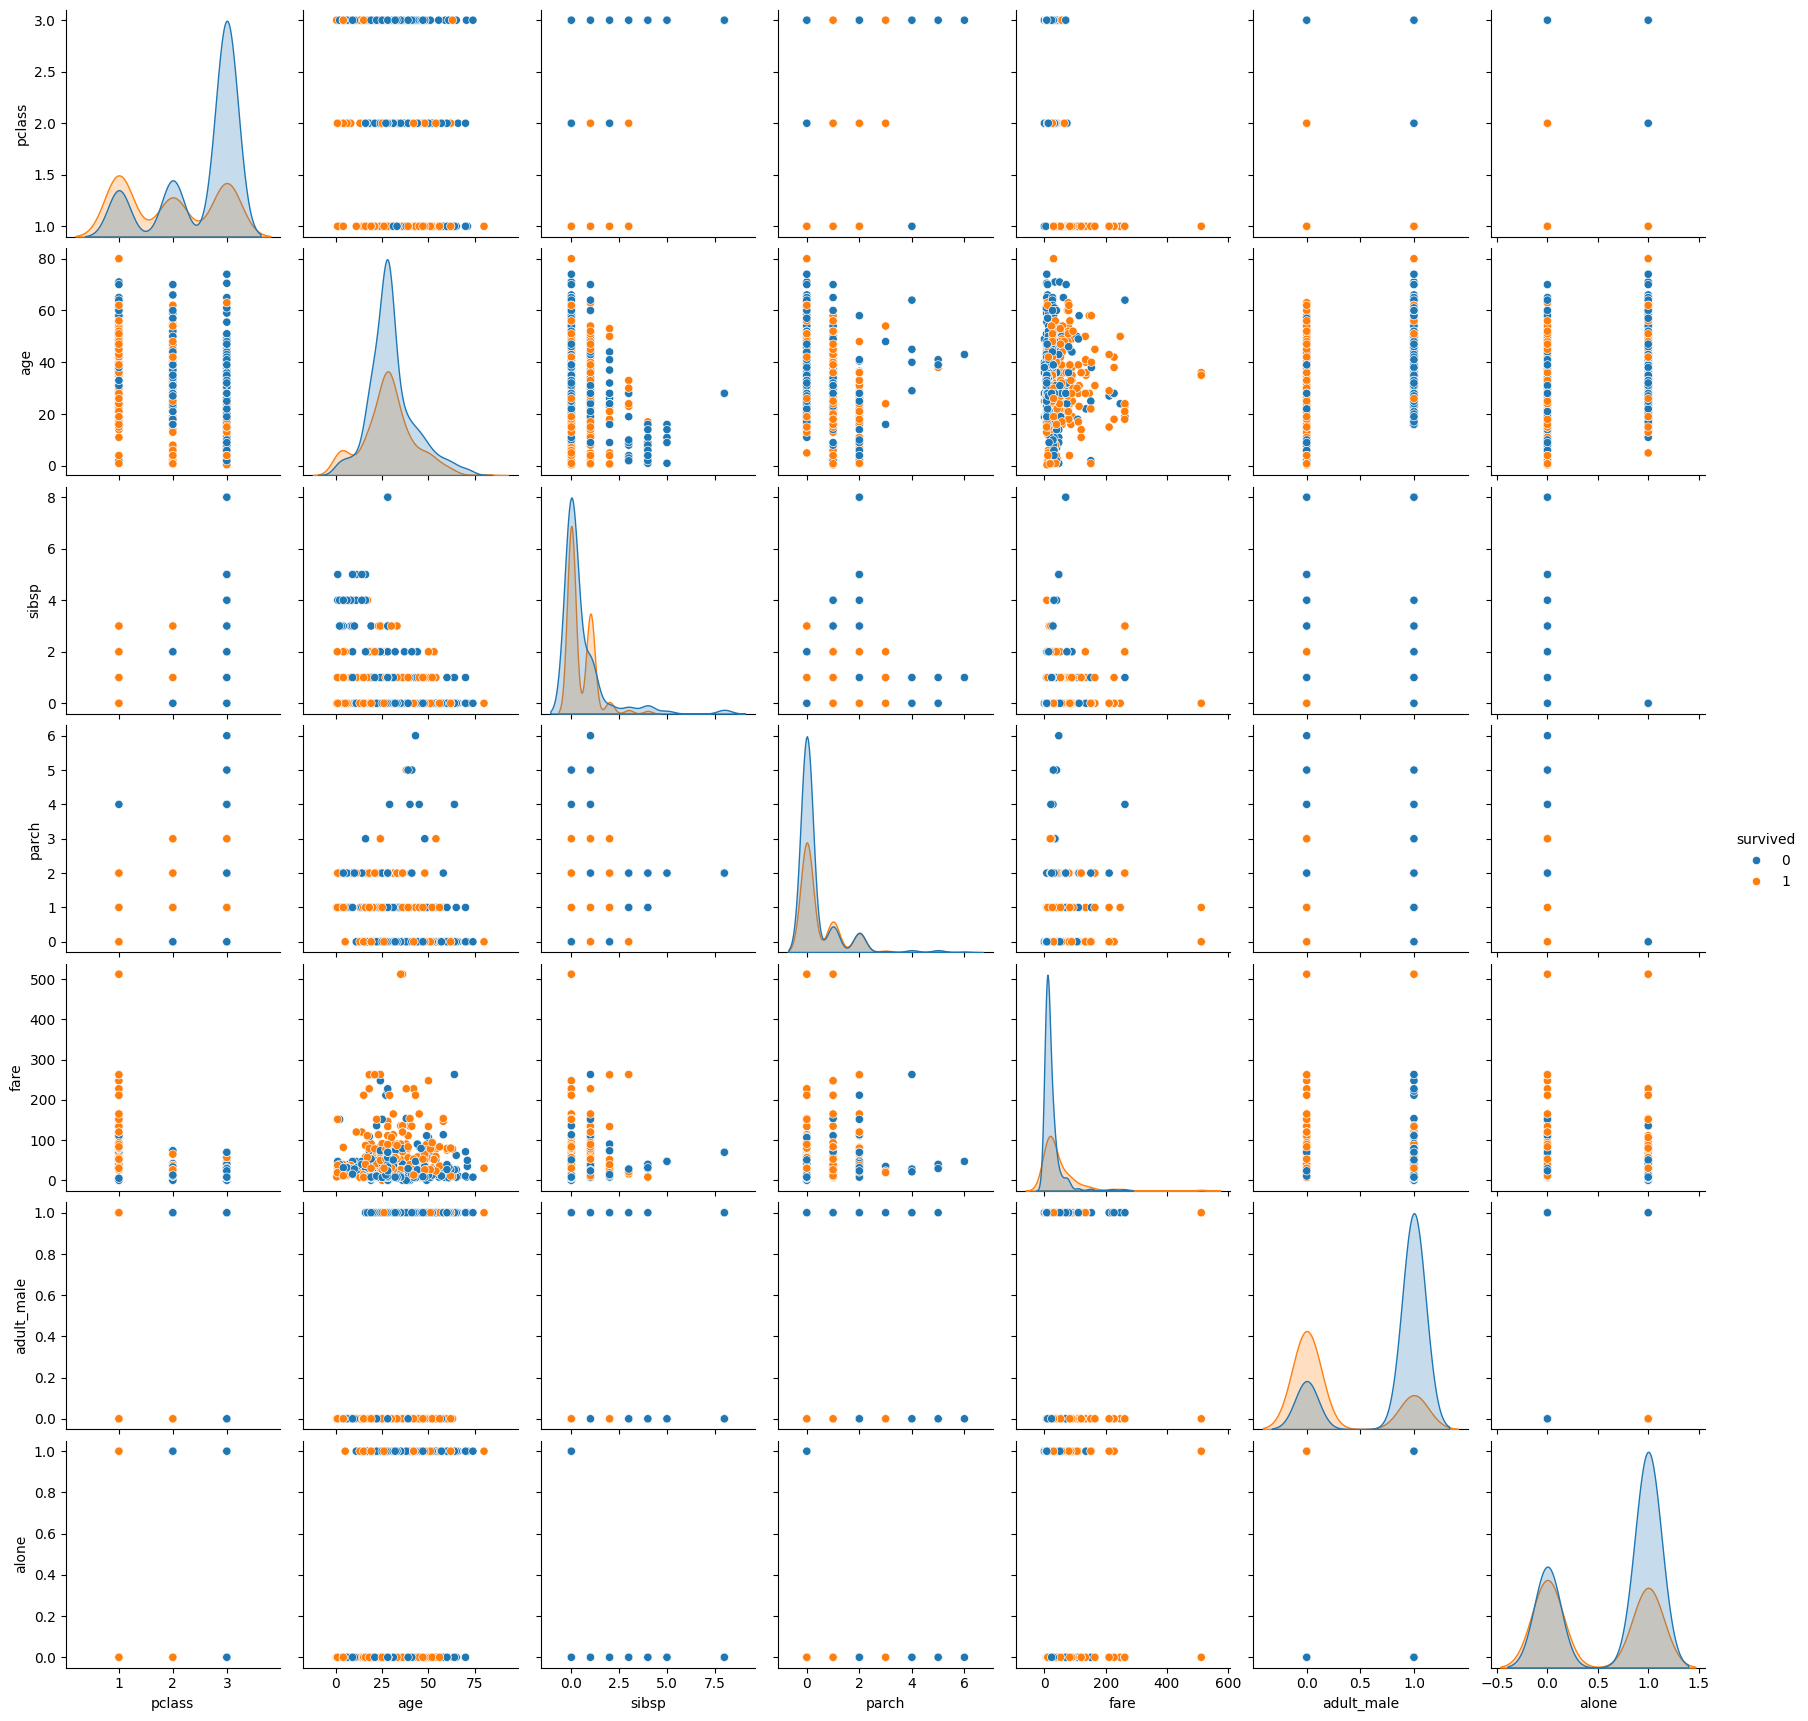

In [56]:
sns.pairplot(titanic, hue = 'survived')

plt.show()

### 7.2 두 변수의 상관관계 시각화하기

#### - 객실 등급과 생존의 상관관계를 seaborn 패키지의 catplot으로 시각화해보자

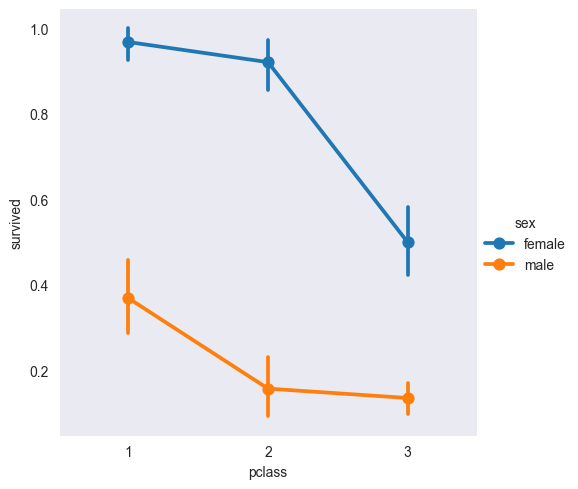

In [ ]:
#여성과 남성의 생존률 차이를 보고싶음(pclass와 survived를 x,y로 지정)
sns.catplot(x = 'pclass', y = 'survived', hue = 'sex', data = titanic, kind = 'point')

plt.show()

In [58]:
bins = [0, 19, 29, 39, 49, 59, 100]
labels = ['Under 20', '20s', '30s', '40s', '50s', '60s+']
titanic['age_group'] = pd.cut(titanic['age'], bins=bins, labels=labels)

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data=None, **kwargs) -> 'list[Line2D]'>

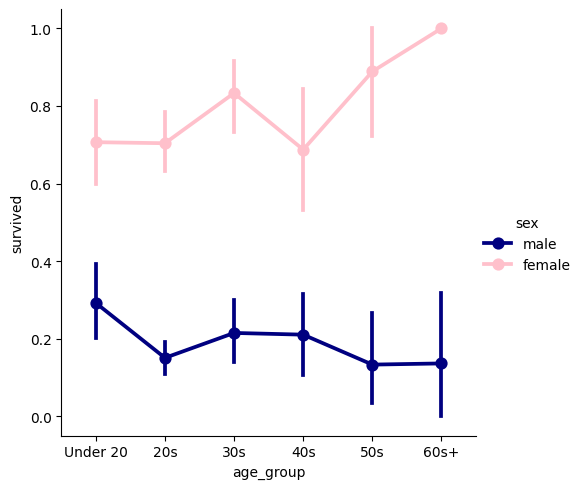

In [61]:
sns.catplot(x='age_group', y = 'survived', hue = 'sex', data = titanic, kind = 'point', palette= ['navy','pink'])
plt.plot

### 7.3 변수 사이의 상관 계수를 히트맵으로 시각화하기

In [62]:
def category_age(x):
    if x < 10:
        return 0
    elif x < 20:
        return 1
    elif x < 30:
        return 2
    elif x < 40:
        return 3
    elif x < 50:
        return 4
    elif x < 60:
        return 5
    elif x < 70:
        return 6
    else:
        return 7

In [63]:
titanic['age2'] = titanic['age'].apply(category_age)

In [64]:
titanic['sex'] = titanic['sex'].map({'male':1, 'female':0})

In [65]:
titanic['family'] = titanic['sibsp'] + titanic['parch'] + 1

In [66]:
titanic.to_csv('./7장_data/titanic3.csv', index = False)

In [67]:
heatmap_data = titanic[['survived', 'sex', 'age2', 'family', 'pclass', 'fare']]

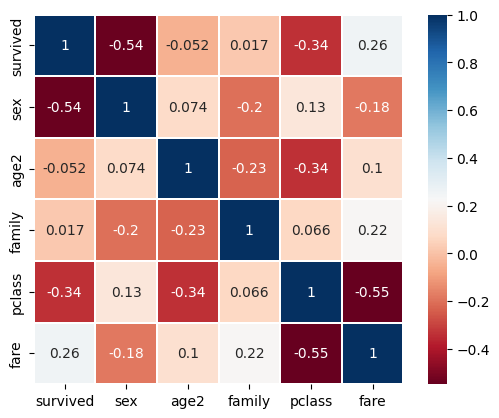

In [ ]:
colormap = plt.cm.RdBu

sns.heatmap(heatmap_data.astype(float).corr(), linewidths = 0.1, vmax = 1.0, square = True, cmap = colormap, linecolor = 'white', annot = True,
annot_kws = {"size": 10})

plt.show()

In [75]:
penguins = sns.load_dataset("penguins")

In [88]:
#1번
penguins.isnull().sum()

species               0
island                0
bill_length_mm        0
bill_depth_mm         0
flipper_length_mm     0
body_mass_g           2
sex                  11
dtype: int64

In [80]:
penguins['bill_length_mm'].mean()
penguins['bill_length_mm'] = penguins['bill_length_mm'].fillna(44)

In [84]:
penguins['bill_depth_mm'].mean()
penguins['bill_depth_mm'] = penguins['bill_depth_mm'].fillna(17)

In [87]:
penguins['flipper_length_mm'].mean()
penguins['flipper_length_mm'] = penguins['flipper_length_mm'].fillna(200)

In [ ]:
penguins['body_mass_g'].mean()
penguins['body_mass_g'] = penguins['body_mass_g'].fillna(4201)

In [93]:
penguins['sex']= penguins['sex'].fillna('Male')

In [95]:
penguins.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [133]:
#1번
print(f"부리 길이-{round(penguins['bill_length_mm'].mean(),2)}",end=' ')
penguins['bill_length_mm'] = penguins['bill_length_mm'].fillna(44)
print(f"부리 두께-{round(penguins['bill_depth_mm'].mean(),2)}",end= ' ')
penguins['bill_depth_mm'] = penguins['bill_depth_mm'].fillna(17)
print(f"날개 길이-{round(penguins['flipper_length_mm'].mean(),2)}",end=' ')
penguins['flipper_length_mm'] = penguins['flipper_length_mm'].fillna(200)
print(f"펭윙 무게-{penguins['body_mass_g'].mean()}")
penguins['body_mass_g'] = penguins['body_mass_g'].fillna(4201)
penguins['sex']= penguins['sex'].fillna('Male')
print(penguins.isnull().sum())

부리 길이-43.92 부리 두께-17.15 날개 길이-200.91 펭윙 무게-4201.75
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
flipper_group        0
flipper_rank         0
dtype: int64


In [ ]:
#2번
penguins2 = penguins.select_dtypes(include=[int, float, bool]) 
penguins_corr = penguins2.corr(method = 'pearson')
penguins_corr
#nan 값들을 제거한 펭귄에서 int형 float형 bool형인 데이터들만 뽑아서 다시 저장하고 피어슨 방식으로 상관관계 분석

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235055,0.656167,0.595109
bill_depth_mm,-0.235055,1.000000,-0.583805,-0.471907
flipper_length_mm,0.656167,-0.583805,1.000000,0.871191
body_mass_g,0.595109,-0.471907,0.871191,1.000000


0.595109389685098


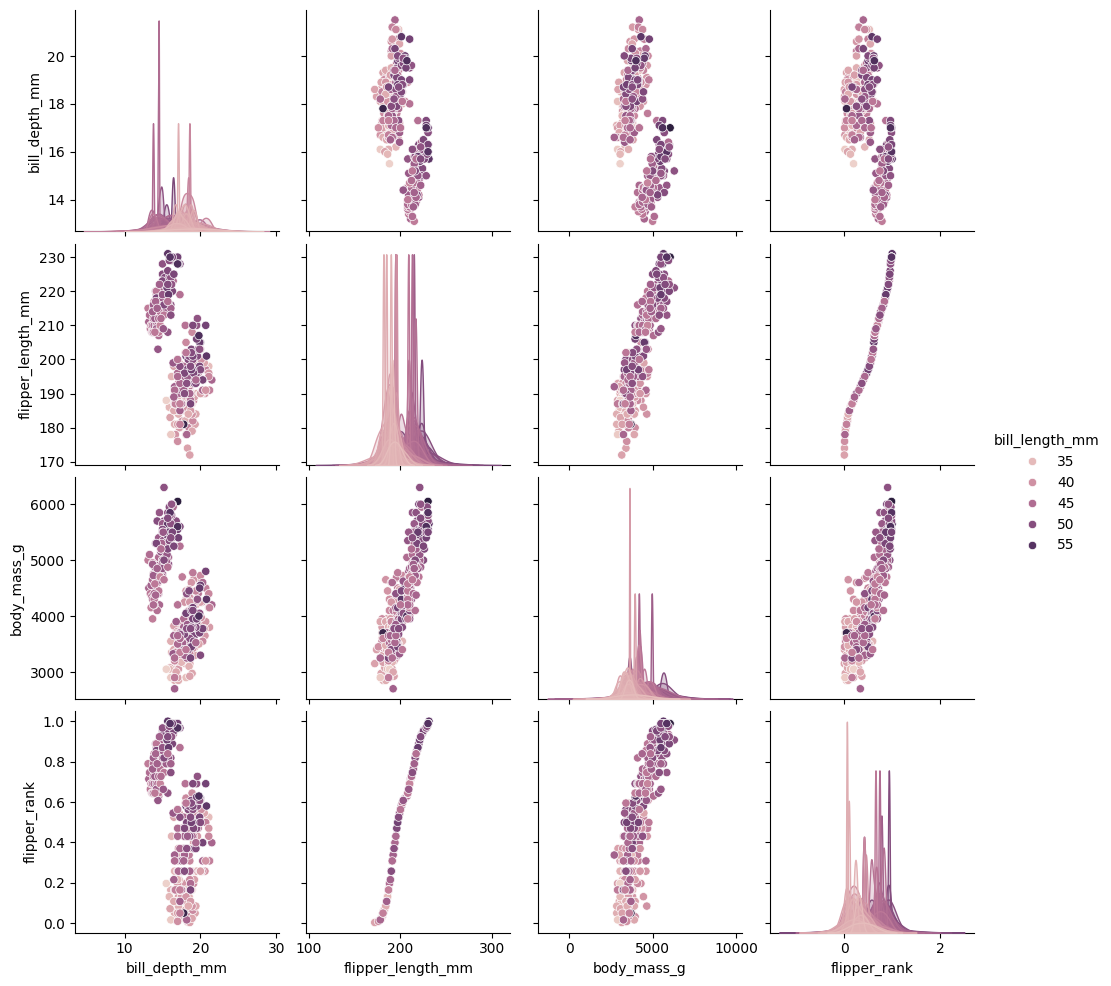

In [ ]:
#3번
#부리 길이와 몸무게의 상관관계만 계산 - 0.59면 꽤 일관되게 늘어나는 경향을 보인다.
print(penguins['bill_length_mm'].corr(penguins['body_mass_g']))

sns.pairplot(penguins, hue = 'bill_length_mm')

plt.show()

In [106]:
penguins.head(0)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


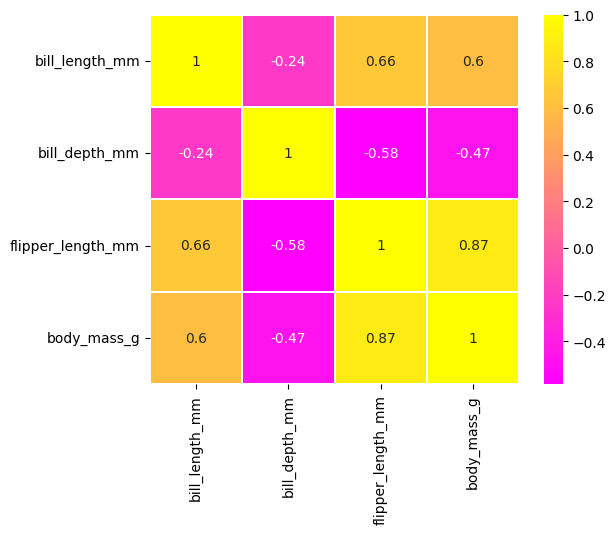

In [ ]:
#4번 수치형 변수만 선택해서 히트맵 그리기
heatmap_data = penguins[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm','body_mass_g']]

colormap = plt.cm.spring

sns.heatmap(heatmap_data.astype(float).corr(), linewidths = 0.1, vmax = 1.0, square = True, cmap = colormap, linecolor = 'white', annot = True,
annot_kws = {"size": 10})

plt.show()

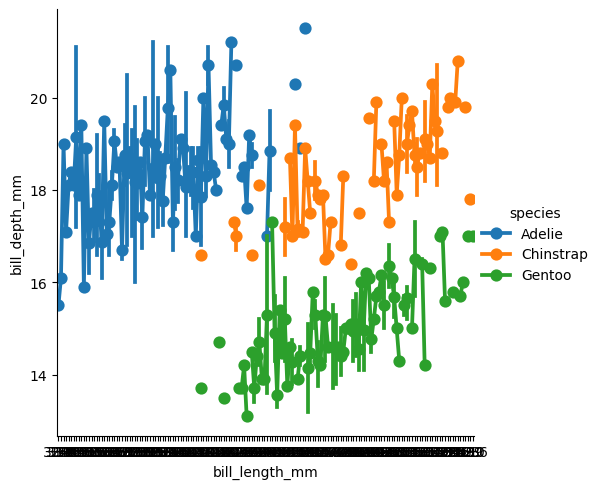

In [123]:
#여성과 남성의 생존률 차이를 보고싶음
sns.catplot(x = 'bill_length_mm', y = 'bill_depth_mm', hue = 'species', data = penguins, kind = 'point')

plt.show()

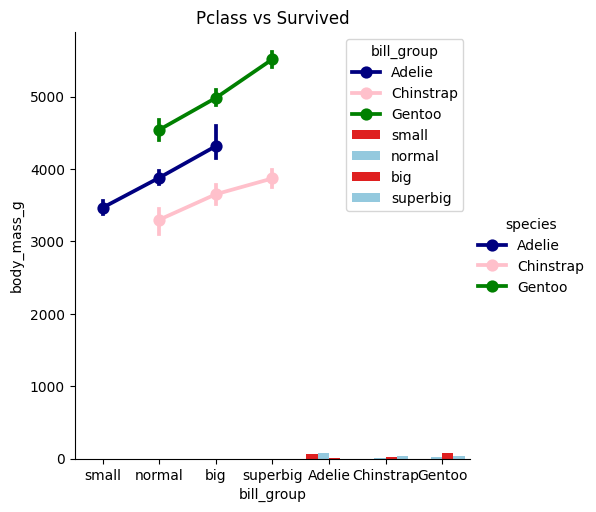

In [144]:
#countplot 갯수를 세서 막대그래프로 보여준다.
penguins['bill_rank'] = penguins['bill_length_mm'].rank(pct=True)
bins = [0, 0.2, 0.5, 0.8 ,1]
labels = ['small','normal','big','superbig']
penguins['bill_group'] = pd.cut(penguins['bill_rank'], bins=bins, labels=labels)
sns.catplot(x='bill_group', y = 'body_mass_g', hue = 'species', data = penguins, kind = 'point', palette= ['navy','pink','green'])
plt.plot
sns.countplot(x='species', hue = 'bill_group', data = penguins, palette=['red','skyblue'])
plt.title('Pclass vs Survived')
plt.show()

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data=None, **kwargs) -> 'list[Line2D]'>

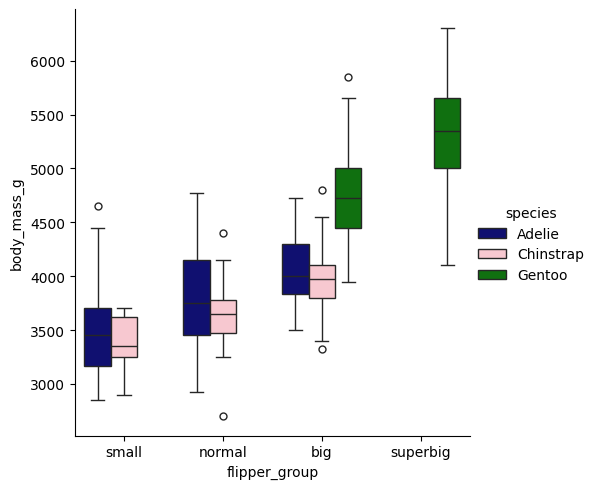

In [154]:
#6번
#펭귄의 날개 길이를 백분율로 나누어서 4개의 그룹으로 분류해주었음
#젠투의 경우 날개 길이가 길며 동시에 무게가 많이 나가며
#나머지 아델리와 친스트랩의 경우는 날개 길이와 무게가 비슷하다.
penguins['flipper_rank'] = penguins['flipper_length_mm'].rank(pct=True)
bins = [0, 0.2, 0.5, 0.8 ,1]
labels = ['small','normal','big','superbig']
penguins['flipper_group'] = pd.cut(penguins['flipper_rank'], bins=bins, labels=labels)
sns.catplot(x='flipper_group', y = 'body_mass_g', hue = 'species', data = penguins, kind = 'box', palette= ['navy','pink','green'])
plt.plot

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data=None, **kwargs) -> 'list[Line2D]'>

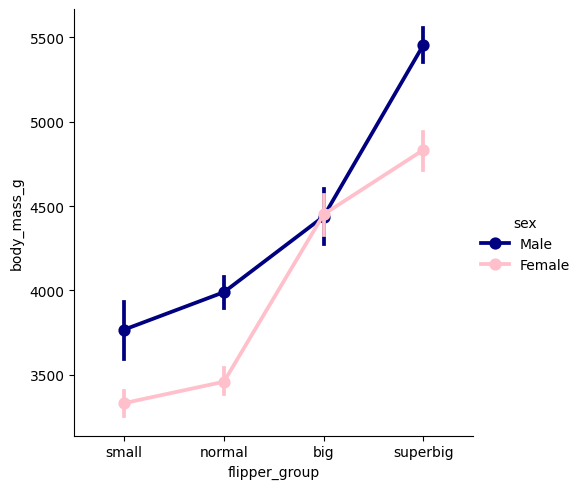

In [138]:
sns.catplot(x='flipper_group', y = 'body_mass_g', hue = 'sex', data = penguins, kind = 'point', palette= ['navy','pink'])
plt.plot

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data=None, **kwargs) -> 'list[Line2D]'>

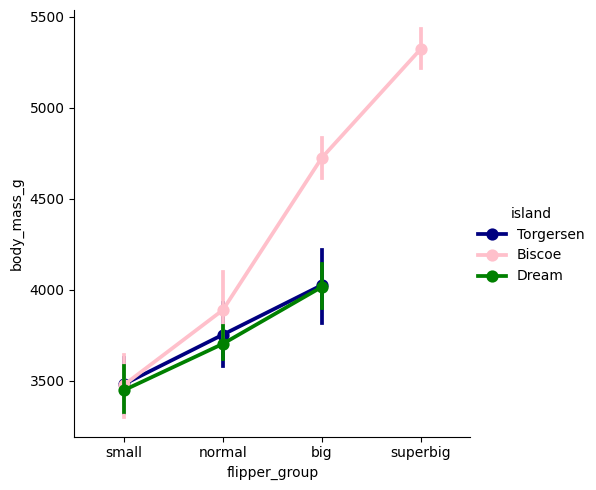

In [ ]:
#비스코 지역에 젠투가 살아서 이런식으로 그래프가 그려지는것 같다.
sns.catplot(x='flipper_group', y = 'body_mass_g', hue = 'island', data = penguins, kind = 'point', palette= ['navy','pink','green'])
plt.plot

In [152]:
import nltk
nltk.download()

showing info https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/index.xml


True